### Rhinozelfant – Lösung Schritt für Schritt

*35. Bundeswettbewerb Informatik (2016), 1. Runde, Aufgabe 2*

Im Urwald von Informatien ist ein Rhinozelfant gefunden worden. Die Forscher sind begeistert: Zum ersten Mal seit Jahrhunderten wurde ein bislang unbekanntes Großtier entdeckt. Es stellt sich die Frage, warum diese Tiere so lange verborgen geblieben sind. Offenbar verfügen sie über einen besonders guten Tarnmechanismus.

Nachdem die ersten Rhinozelfanten in einen Zoo gebracht wurden, stellten die Tierpfleger fest, dass diese – ähnlich wie Chamäleons – die Farbe ihrer Haut an beliebige Umgebungen anpassen können. Wenn ein Rhinozelfant merkt, dass es beobachtet wird, nimmt jede seiner Hautschuppen die Umgebungsfarbe der dem Betrachter gegenüberliegenden Körperseite an. Dadurch wird es für den Beobachter quasi „durchsichtig“.

Mit modernen Digitalkameras ist es allerdings möglich, Rhinozelfanten zu erkennen: Wenn die Auflösung nur hoch genug ist, wird jede Hautschuppe durch mehrere nebeneinander liegende Pixel dargestellt. Weil alle diese Pixel dieselbe Schuppe abbilden, haben sie genau die gleiche Farbe. Dadurch kann man feststellen, welche Pixel in einem Bild möglicherweise einen Rhinozelfanten darstellen.

Es sollen nun mehrere Fotos aus dem Rhinozelfantenwald geprüft werden, ob darauf vielleicht ein Rhinozelfant abgebildet ist.

#### Aufgabe 2

Erstelle ein Programm, das diejenigen Pixel eines Bildes weiß färbt, die zu einem Rhinozelfanten gehören könnten.

Unter bundeswettbewerb-informatik.de sind einige Fotos zur Verfügung gestellt. Auf welchen ist ein Rhinozelfant abgebildet?

**Zu den Beispieldaten:** Es gibt neun Fotos (`rhinozelfant1` bis `rhinozelfant9`, je 1 bis 6 Megapixel). Im Ordner `beispieldaten` liegt nur `rhinozelfant1.png`. Die anderen acht gibt es nur als große ZIP-Archive auf https://bwinf.de/bundeswettbewerb/35/1/ (`RhinozelfantPNG.zip`, 71 MB). Dieses Notebook rechnet deshalb nur mit Bild 1 und mit eigenen kleinen Testbildern. Die Ergebnisse für alle neun Bilder habe ich mit denselben Regeln vorab berechnet und trage sie in einer Tabelle ein.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Nachbarn eines Gitterpunkts:** Ein Bild ist ein Gitter aus Pixeln. Jedes Pixel hat bis zu vier Nachbarn (oben, unten, links, rechts). Am Rand fehlen manche; dort darf man nicht außerhalb der Liste lesen.
- **Ergebnis in ein neues Bild schreiben:** Würde man das Bild beim Prüfen gleich weiß färben, würden schon gefärbte Pixel die Prüfung der nächsten Pixel verfälschen (weiß wäre dann plötzlich eine „gleiche Farbe“). Deshalb prüft man im Original und schreibt in eine Kopie.
- **Zwei verschachtelte Schleifen** über Zeilen und Spalten (zweidimensionale Liste).

**Nützliche Funktionen und Bibliotheken**
- **Pillow** (`from PIL import Image`): `Image.open(...)` öffnet ein Bild, `.convert('RGB')` sorgt für drei Werte je Pixel, `.size` liefert Breite und Höhe, `list(bild.getdata())` die Pixel als Liste von Tupeln `(rot, grün, blau)`. Zwei Tupel vergleicht man mit `==`.
- **matplotlib** (`plt.imshow`) zeigt eine Liste von Zeilen aus Farbtupeln als Bild an (hier nur zur Anzeige).

## Die Idee

Eine Hautschuppe wird durch **mehrere nebeneinander liegende Pixel** mit **genau derselben Farbe** abgebildet. Jedes Pixel einer Schuppe hat dann mindestens einen Nachbarn (links, rechts, oben oder unten) mit derselben Farbe. Das ist unser Kriterium:

> Ein Pixel **könnte zu einem Rhinozelfanten gehören**, wenn mindestens eines seiner vier Nachbarpixel **genau** die gleiche Farbe hat. Dann färben wir es weiß.

Bei einem normalen Foto rauscht die Kamera: Zwei benachbarte Pixel haben meist nicht exakt dieselben Rot-, Grün- und Blauwerte. Die Umgebung bleibt also unverändert farbig, und nur die Rhinozelfantenschuppen (sowie ein paar zufällig gleiche Pixel, siehe unten) werden weiß. Dann sieht man das Tier als weiße Fläche.

**Warum alle vier Nachbarn?** Prüft man nur einen Nachbarn (z. B. nur den rechten), dann bekommt das letzte Pixel jeder Schuppenzeile keine Markierung, und es entstehen Streifen am Rand. Alle vier Richtungen vermeiden das, das macht auch der Vorschlag der Lösungshinweise.

Ob wirklich ein Rhinozelfant zu sehen ist, entscheidet am Ende der Mensch am Bildschirm.

## Schritt 1: Ein kleines Testbild

Wir bauen uns ein Bild von Hand, damit wir das Verfahren prüfen können. Ein Bild ist eine Liste von Zeilen, jede Zeile eine Liste von Farben `(rot, grün, blau)`. Hier gibt es vier Farben: `a`, `b`, `c`, `d`. Die Farbe `a` kommt in einem 2×3-Block vor (die „Schuppe“), alle anderen Pixel haben jeweils nur zufällig etwas Passendes in der Nähe oder gar nichts.

In [ ]:
a = (10, 200, 30)
b = (11, 199, 31)
c = (12, 201, 29)
d = (13, 198, 32)

test = [[b, c, d, b, c],
        [c, a, a, a, d],
        [d, a, a, a, b],
        [b, d, c, b, d],
        [c, b, d, d, a]]


def zeige_zeilen(bild):
    """Gibt jedes Pixel als Buchstabe aus (nur für unser Testbild mit den Farben a bis d)."""
    namen = {a: 'a', b: 'b', c: 'c', d: 'd', (255, 255, 255): 'W'}
    for zeile in bild:
        print(' '.join(namen[p] for p in zeile))


zeige_zeilen(test)

b c d b c
c a a a d
d a a a b
b d c b d
c b d d a


Von Hand gedacht: Alle sechs `a` im Block haben einen gleichfarbigen Nachbarn. Außerdem stehen unten zwei `d` nebeneinander (Zeile 5, Spalten 3 und 4). Das `a` in der Ecke unten rechts hat keinen `a`-Nachbarn. Sonst gibt es keine gleichen Nachbarn. Es müssten also genau **8 Pixel** weiß werden.

## Schritt 2: Hat ein Pixel einen gleichfarbigen Nachbarn?

Zuerst eine Funktion für ein einzelnes Pixel in Zeile `i` und Spalte `j`. Die Bedingungen `i > 0` usw. verhindern, dass wir über den Rand hinaus lesen. Beachte: In Python bedeutet `bild[-1]` das **letzte** Element. Ohne die Randprüfung würde man bei `i = 0` also die letzte Zeile als „Nachbarn“ vergleichen, ohne Fehlermeldung. Das wäre ein stiller Fehler.

In [ ]:
def hat_gleichen_nachbarn(bild, i, j):
    """True, wenn mindestens eines der vier Nachbarpixel von (i, j) genau dieselbe Farbe hat."""
    hoehe = len(bild)
    breite = len(bild[0])
    farbe = bild[i][j]
    if i > 0 and bild[i - 1][j] == farbe:             # oben
        return True
    if i < hoehe - 1 and bild[i + 1][j] == farbe:     # unten
        return True
    if j > 0 and bild[i][j - 1] == farbe:             # links
        return True
    if j < breite - 1 and bild[i][j + 1] == farbe:    # rechts
        return True
    return False


print(hat_gleichen_nachbarn(test, 1, 1))    # a im Block
print(hat_gleichen_nachbarn(test, 4, 4))    # einzelnes a in der Ecke
print(hat_gleichen_nachbarn(test, 0, 0))    # b in der Ecke oben links

True
False
False


## Schritt 3: Das ganze Bild

Jetzt zwei verschachtelte Schleifen. Das Ergebnis schreiben wir in eine **neue** Liste, das Original bleibt unverändert. Pixel ohne gleichen Nachbarn behalten ihre Farbe, die anderen werden weiß. Zusätzlich zählen wir mit, wie viele Pixel wir weiß gefärbt haben (nicht einfach alle weißen Pixel zu zählen: Im Original kann es schon reinweiße Pixel geben).

In [ ]:
WEISS = (255, 255, 255)


def markiere(bild):
    """Liefert ein neues Bild (Pixel mit gleichfarbigem Nachbarn werden weiß, die anderen bleiben, wie sie sind)
    und die Anzahl der weiß gefärbten Pixel."""
    ergebnis = []
    anzahl = 0
    for i in range(len(bild)):
        zeile = []
        for j in range(len(bild[0])):
            if hat_gleichen_nachbarn(bild, i, j):
                zeile.append(WEISS)
                anzahl += 1
            else:
                zeile.append(bild[i][j])
        ergebnis.append(zeile)
    return ergebnis, anzahl


ergebnis_test, anzahl_test = markiere(test)
zeige_zeilen(ergebnis_test)
print('weiß gefärbte Pixel:', anzahl_test)

b c d b c
c W W W d
d W W W b
b d c b d
c b W W a
weiß gefärbte Pixel: 8


Genau die erwarteten 8 Pixel sind weiß: der 2×3-Block und das `d`-Paar.

**Warum nicht gleich im Original färben?** Das Original bleibt unverändert, weil sonst ein frisch gefärbtes weißes Pixel beim nächsten Pixel wie ein „gleicher Nachbar“ wirken könnte, wenn dieses ebenfalls weiß wäre. Auch das liefe ohne Fehlermeldung, aber mit falschem Ergebnis.

## Schritt 4: Ein echtes Foto einlesen

Jetzt `rhinozelfant1.png` (576 × 1024 Pixel). Mit Pillow lesen wir die Pixel als flache Liste ein und schneiden sie in Zeilen der Breite `breite` auf.

In [ ]:
from PIL import Image


def lade_bild(dateiname):
    """Liest ein Bild und gibt es als Liste von Zeilen aus Farbtupeln (rot, grün, blau) zurück."""
    foto = Image.open(dateiname).convert('RGB')
    breite, hoehe = foto.size
    pixel = list(foto.getdata())
    return [pixel[zeile * breite:(zeile + 1) * breite] for zeile in range(hoehe)]


bild1 = lade_bild('beispieldaten/rhinozelfant1.png')
print('Höhe:', len(bild1), 'Breite:', len(bild1[0]), 'Pixel:', len(bild1) * len(bild1[0]))
print('erstes Pixel:', bild1[0][0])
farben1 = set()
for zeile in bild1:
    for pixel in zeile:
        farben1.add(pixel)
print('verschiedene Farben:', len(farben1))

Höhe: 1024 Breite: 576 Pixel: 589824
erstes Pixel: (198, 222, 222)
verschiedene Farben: 2822


Bei einem Foto mit 590 000 Pixeln gibt es nur rund 2800 verschiedene Farben, also teilen sich viele Pixel eine Farbe. Wir markieren jetzt und zeigen Original und Ergebnis nebeneinander.

weiß gefärbte Pixel: 206274 von 589824
Anteil: 35.0 %


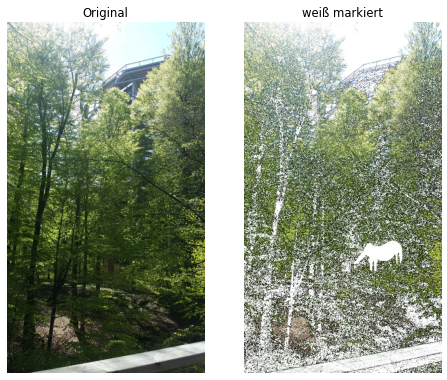

In [ ]:
import matplotlib.pyplot as plt

markiert1, weiss1 = markiere(bild1)
print('weiß gefärbte Pixel:', weiss1, 'von', len(bild1) * len(bild1[0]))
print('Anteil: %.1f %%' % (100 * weiss1 / (len(bild1) * len(bild1[0]))))

bilder_paar, achsen = plt.subplots(1, 2, figsize=(8, 7))
achsen[0].imshow(bild1)
achsen[0].set_title('Original')
achsen[1].imshow(markiert1)
achsen[1].set_title('weiß markiert')
for achse in achsen:
    achse.axis('off')

In der unteren Bildhälfte sieht man bei den Büschen eine zusammenhängende weiße Fläche in Tierform: ein **Rhinozelfant**. Das passt zu den Lösungshinweisen, die für Bild 1 „Rhinozelfant: ja“ angeben. Auch an anderen Stellen (vor allem in hellen Bereichen oben) sind viele Pixel weiß, weil dort zufällig viele Nachbarn exakt gleich sind. Das stört nicht, weil man das Tier an seinem Umriss erkennt. Je höher der weiße Anteil der Gesamtfläche ist, desto schwerer wird das Erkennen.

## Schritt 5: Warum alle vier Nachbarn?

Zur Kontrolle der Begründung oben vergleichen wir am Testbild mit einer Variante, die nur den **rechten** Nachbarn prüft.

In [ ]:
def markiere_nur_rechts(bild):
    """Falsche Variante: nur der rechte Nachbar wird verglichen."""
    ergebnis = []
    for i in range(len(bild)):
        zeile = []
        for j in range(len(bild[0]) - 1):
            if bild[i][j] == bild[i][j + 1]:
                zeile.append(WEISS)
            else:
                zeile.append(bild[i][j])
        zeile.append(bild[i][-1])           # letzte Spalte: kein rechter Nachbar
        ergebnis.append(zeile)
    return ergebnis


print('vier Nachbarn:')
zeige_zeilen(ergebnis_test)
print()
print('nur rechter Nachbar:')
zeige_zeilen(markiere_nur_rechts(test))

vier Nachbarn:
b c d b c
c W W W d
d W W W b
b d c b d
c b W W a

nur rechter Nachbar:
b c d b c
c W W a d
d W W a b
b d c b d
c b W d a


Mit dem rechten Nachbarn allein fehlt jeweils das **letzte** Pixel jeder Schuppenzeile (das rechte `a` bleibt farbig), und das `d`-Paar wird nur halb gefärbt. Bei einem ganzen Rhinozelfanten bleibt so ein Rand von Pixeln farbig. Das zeigen die Lösungshinweise als Streifen im Ergebnisbild. Mit allen vier Richtungen wird jede Schuppe vollständig weiß.

## Alle neun Bilder

Dieselben Regeln habe ich für alle neun Fotos aus `RhinozelfantPNG.zip` laufen lassen (dort mit numpy, weil 6 Megapixel in reinem Python lange dauern; für Bild 1 ergibt numpy denselben weißen Anteil wie die Funktion oben, siehe nächster Abschnitt). Auf dem Ergebnisbild habe ich nachgesehen, ob eine zusammenhängende weiße Tierform zu erkennen ist:

| Bild | Größe | weißer Anteil | Rhinozelfant? |
|---|---|---|---|
| 1 | 576 × 1024 | 35,0 % | **ja** (kleiner, unten) |
| 2 | 3000 × 2000 | 30,2 % | **ja** (groß, in der Mitte) |
| 3 | 2000 × 3000 | 19,7 % | nein |
| 4 | 2000 × 3000 | 30,3 % | **ja** (links, am Bach) |
| 5 | 3000 × 2000 | 19,0 % | nein |
| 6 | 3000 × 2000 | 28,4 % | nein |
| 7 | 2000 × 3000 | 25,7 % | nein |
| 8 | 2000 × 3000 | 19,2 % | **ja** (unten, im Gras) |
| 9 | 3000 × 2000 | 24,4 % | **ja** (oben in der Mitte) |

Das stimmt mit den Lösungshinweisen überein: **Rhinozelfanten sind auf den Bildern 1, 2, 4, 8 und 9 zu sehen.** Der weiße Anteil allein verrät den Rhinozelfanten nicht (Bild 3 hat 19,7 %, Bild 4 hat 30,3 %): Er hängt auch davon ab, wie rauschfrei ein Foto ist. Erst die **Form** der weißen Fläche zeigt das Tier.

Wer die anderen Bilder selbst prüfen will, lädt sie von der BWINF-Seite und ruft `lade_bild` und `markiere` auf, eventuell nach Verkleinern auf einen Ausschnitt, damit es nicht zu lange dauert.

## Für Neugierige: schneller mit numpy

Die Schleifen oben brauchen für Bild 1 einige Sekunden. Mit der Bibliothek **numpy** lässt sich das ganze Bild auf einmal vergleichen: `a[:, 1:] == a[:, :-1]` vergleicht jedes Pixel mit seinem linken Nachbarn, `.all(axis=2)` verlangt, dass alle drei Farbwerte gleich sind. Aus den Treffern für „Pixel gleich seinem Nachbarn“ markieren wir beide Pixel des Paares. Hier die Probe, dass das dasselbe liefert wie unsere Funktion:

In [ ]:
import numpy as np


def markiere_numpy(bild):
    a = np.array(bild)
    weiss = np.zeros(a.shape[:2], dtype=bool)
    gleich = (a[:, 1:] == a[:, :-1]).all(axis=2)     # Paare nebeneinander
    weiss[:, 1:] |= gleich
    weiss[:, :-1] |= gleich
    gleich = (a[1:] == a[:-1]).all(axis=2)           # Paare übereinander
    weiss[1:] |= gleich
    weiss[:-1] |= gleich
    return weiss


weiss_np = markiere_numpy(bild1)
print('weiße Pixel mit numpy:', int(weiss_np.sum()))
print('gleiche Menge wie die Schleifen:', int(weiss_np.sum()) == weiss1)

weiße Pixel mit numpy: 206274
gleiche Menge wie die Schleifen: True


**Weitere Gedanken:** Statt „genau gleich“ könnte man auch „fast gleich“ (kleiner Abstand der Farbwerte) zulassen. Das wäre aber schwerer zu begründen und würde auch viele Pixel von Wiesen oder Himmel erfassen. Die Aufgabe sagt „genau die gleiche Farbe“, also nehmen wir genau gleich.

## Zum Schluss: Geht das mit MiniZinc?

Technisch ja, **sinnvoll** ist es hier aber nicht. MiniZinc ist für Probleme gedacht, bei denen ein Solver etwas **suchen** muss (Zuordnungen, Pläne, Rätsel). Hier gibt es nichts zu suchen: Für jedes Pixel ist das Ergebnis direkt aus den Nachbarn ablesbar, also eine reine Berechnung. Ich habe es trotzdem gemessen, mit diesem Modell (`rhinozelfant.mzn`). Jede Farbe wird dazu als eine Zahl `rot * 65536 + grün * 256 + blau` übergeben; die Bedingung „Nachbar mit derselben Farbe“ steht in einer Array-Comprehension, die mit `\/` (oder) und `/\` (und) die Randfälle abfängt:

```minizinc
int: H;                                   % Höhe
int: W;                                   % Breite
array[1..H, 1..W] of int: f;              % Farbe als Zahl rot*65536 + grün*256 + blau

% weiss[i,j] = 1, wenn mindestens ein Nachbar dieselbe Farbe hat
array[1..H, 1..W] of 0..1: weiss = array2d(1..H, 1..W,
  [ bool2int( (i > 1 /\ f[i-1, j] = f[i, j]) \/ (i < H /\ f[i+1, j] = f[i, j])
           \/ (j > 1 /\ f[i, j-1] = f[i, j]) \/ (j < W /\ f[i, j+1] = f[i, j]) )
  | i in 1..H, j in 1..W ]);

solve satisfy;
output ["\(sum(i in 1..H, j in 1..W)(weiss[i, j]))\n"];
```

Test mit unserem 5×5-Testbild von oben (Farben `a` bis `d` als 1 bis 4 geschrieben, Daten als `.dzn`-Datei):

**Ausgabe:**

```
8
```

Das sind dieselben **8 weißen Pixel** wie in Python. Für das echte Bild 1 erzeugt die folgende Python-Zelle die Datendatei `rhinozelfant1.dzn` (590 000 Zahlen):

In [ ]:
def als_dzn(bild):
    """Bild als MiniZinc-Daten: Farbe = rot * 65536 + grün * 256 + blau."""
    zahlen = []
    for zeile in bild:
        for (r, g, b) in zeile:
            zahlen.append(str(r * 65536 + g * 256 + b))
    return 'H = %d;\nW = %d;\nf = array2d(1..H, 1..W, [%s]);\n' % (len(bild), len(bild[0]), ', '.join(zahlen))


dzn1 = als_dzn(bild1)
print('Länge der Datendatei in Zeichen:', len(dzn1))

Länge der Datendatei in Zeichen: 5424366


Mit Gecode in der MiniZinc IDE kommt bei Bild 1 heraus:

**Ausgabe:**

```
206274
```

Das sind genau so viele weiße Pixel wie bei der Python-Lösung (206.274). Bei allen neun Bildern lief Gecode durch (jeweils 0,6 bis 6 Millionen Zellen); Bild 1 brauchte etwa zwei Sekunden, die großen Bilder jeweils rund 20 Sekunden. Ein Vorteil gegenüber Python ist das nicht: Das Modell schreibt nur auf, was die Schleifen auch tun, und liefert hier nicht einmal ein Bild, sondern nur die Anzahl. MiniZinc lohnt sich bei dieser Aufgabe also nicht. Es hilft erst, wenn man etwas **wählen** muss, zum Beispiel „welche Pixel soll man höchstens markieren, damit ...“. Das fragt diese Aufgabe nicht.